<a href="https://colab.research.google.com/github/oabdelhalim8/ML---8/blob/main/ML_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sys

assert sys.version_info >= (3, 10)

In [2]:
from packaging.version import Version
import sklearn

assert Version(sklearn.__version__) >= Version("1.6.1")

In [3]:
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

In [4]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.linear_model import Perceptron

iris = load_iris(as_frame=True)
X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = (iris.target == 0)  # Iris setosa

per_clf = Perceptron(random_state=42)
per_clf.fit(X, y)

X_new = [[2, 0.5], [3, 1]]
y_pred = per_clf.predict(X_new)  # predicts True and False for these 2 flowers

In [5]:
y_pred

array([ True, False])

In [6]:
# extra code – shows how to build and train a Perceptron

from sklearn.linear_model import SGDClassifier

sgd_clf = SGDClassifier(loss="perceptron", penalty=None,
                        learning_rate="constant", eta0=1, random_state=42)
sgd_clf.fit(X, y)
assert (sgd_clf.coef_ == per_clf.coef_).all()
assert (sgd_clf.intercept_ == per_clf.intercept_).all()

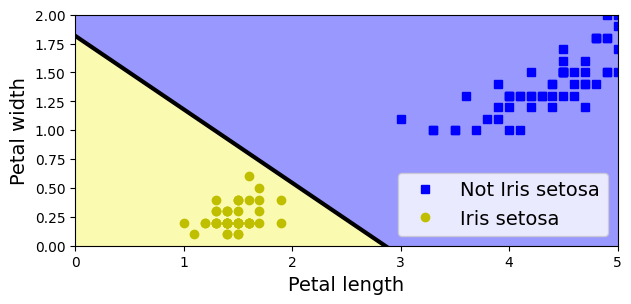

In [7]:
# extra code – plots the decision boundary of a Perceptron on the iris dataset

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

a = -per_clf.coef_[0, 0] / per_clf.coef_[0, 1]
b = -per_clf.intercept_ / per_clf.coef_[0, 1]
axes = [0, 5, 0, 2]
x0, x1 = np.meshgrid(
    np.linspace(axes[0], axes[1], 500).reshape(-1, 1),
    np.linspace(axes[2], axes[3], 200).reshape(-1, 1),
)
X_new = np.c_[x0.ravel(), x1.ravel()]
y_predict = per_clf.predict(X_new)
zz = y_predict.reshape(x0.shape)
custom_cmap = ListedColormap(['#9898ff', '#fafab0'])

plt.figure(figsize=(7, 3))
plt.plot(X[y == 0, 0], X[y == 0, 1], "bs", label="Not Iris setosa")
plt.plot(X[y == 1, 0], X[y == 1, 1], "yo", label="Iris setosa")
plt.plot([axes[0], axes[1]], [a * axes[0] + b, a * axes[1] + b], "k-",
         linewidth=3)
plt.contourf(x0, x1, zz, cmap=custom_cmap)
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.legend(loc="lower right")
plt.axis(axes)
plt.show()

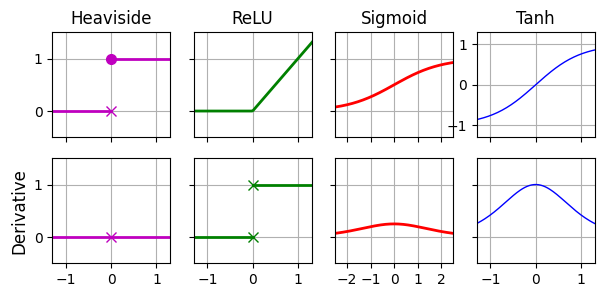

In [8]:
# extra code – this cell generates Figure 9–8

from scipy.special import expit as sigmoid

def relu(z):
    return np.maximum(0, z)

def derivative(f, z, eps=0.000001):
    return (f(z + eps) - f(z - eps)) / (2 * eps)

max_z = 2.5
z = np.linspace(-max_z, max_z, 200)

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(7, 3))

axes[0, 0].plot([-max_z, 0], [0, 0], "m-", linewidth=2)
axes[0, 0].plot(0, 0, "mx", markersize=7)
axes[0, 0].plot(0, 1, "mo", markersize=7)
axes[0, 0].plot([0, max_z], [1, 1], "m-", linewidth=2)
axes[0, 0].set_title("Heaviside", fontsize=12)
axes[1, 0].plot(z, derivative(np.sign, z), "m-", linewidth=2)
axes[1, 0].plot(0, 0, "mx", markersize=7)
axes[1, 0].set_ylabel("Derivative", fontsize=12)

axes[0, 1].plot(z, relu(z), "g-", linewidth=2)
axes[0, 1].set_title("ReLU", fontsize=12)
axes[1, 1].plot([-max_z, 0], [0, 0], "g-", linewidth=2)
axes[1, 1].plot([0, max_z], [1, 1], "g-", linewidth=2)
axes[1, 1].plot(0, 0, "gx", markersize=7)
axes[1, 1].plot(0, 1, "gx", markersize=7)

axes[0, 2].plot(z, sigmoid(z), "r-", linewidth=2)
axes[0, 2].set_title("Sigmoid", fontsize=12)
axes[1, 2].plot(z, derivative(sigmoid, z), "r-", linewidth=2)

axes[0, 3].plot(z, np.tanh(z), "b-", linewidth=1)
axes[0, 3].set_title("Tanh", fontsize=12)
axes[1, 3].plot(z, derivative(np.tanh, z), "b-", linewidth=1)

for row in range(2):
    for col in range(4):
        axes[row, col].grid(True)
        if row == 0:
            axes[row, col].set_xticklabels([])
        if col == 2:
            axes[row, col].set_xlim(-max_z, max_z)
            axes[row, col].set_xticks([-2, -1, 0, 1, 2])
        else:
            axes[row, col].set_xlim(-1.3, 1.3)
            axes[row, col].set_xticks([-1, 0, 1])
        if col != 0 and ((row, col) != (0, 3)):
            axes[row, col].set_yticklabels([])
        if (row, col) == (0, 3):
            axes[row, col].set_ylim(-1.3, 1.3)
            axes[row, col].set_yticks([-1, 0, 1])
        else:
            axes[row, col].set_ylim(-0.5, 1.5)
            axes[row, col].set_yticks([0, 1])

plt.show()

In [9]:
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [10]:
housing = fetch_california_housing()
X_train, X_test, y_train, y_test = train_test_split(
    housing.data, housing.target, random_state=42)

In [11]:
mlp_reg = MLPRegressor(hidden_layer_sizes=[50, 50, 50], early_stopping=True,
                       verbose=True, random_state=42)

In [12]:
pipeline = make_pipeline(StandardScaler(), mlp_reg)
pipeline.fit(X_train, y_train)

Iteration 1, loss = 0.85190332
Validation score: 0.534299
Iteration 2, loss = 0.28288639
Validation score: 0.651094
Iteration 3, loss = 0.22884372
Validation score: 0.699782
Iteration 4, loss = 0.20746145
Validation score: 0.720468
Iteration 5, loss = 0.19649383
Validation score: 0.724839
Iteration 6, loss = 0.18928708
Validation score: 0.740084
Iteration 7, loss = 0.18132029
Validation score: 0.747406
Iteration 8, loss = 0.17556450
Validation score: 0.753945
Iteration 9, loss = 0.17190651
Validation score: 0.760500
Iteration 10, loss = 0.16687650
Validation score: 0.759213
Iteration 11, loss = 0.16329479
Validation score: 0.761907
Iteration 12, loss = 0.16054473
Validation score: 0.768950
Iteration 13, loss = 0.15690181
Validation score: 0.762699
Iteration 14, loss = 0.15630644
Validation score: 0.766003
Iteration 15, loss = 0.15712517
Validation score: 0.778464
Iteration 16, loss = 0.15155981
Validation score: 0.774237
Iteration 17, loss = 0.14957641
Validation score: 0.778361
Iterat

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('mlpregressor',
                 MLPRegressor(early_stopping=True,
                              hidden_layer_sizes=[50, 50, 50], random_state=42,
                              verbose=True))])

In [13]:
mlp_reg.best_validation_score_

0.791536125425778

In [14]:
y_pred = pipeline.predict(X_test)
rmse = root_mean_squared_error(y_test, y_pred)

In [15]:
rmse

0.5327699946812925

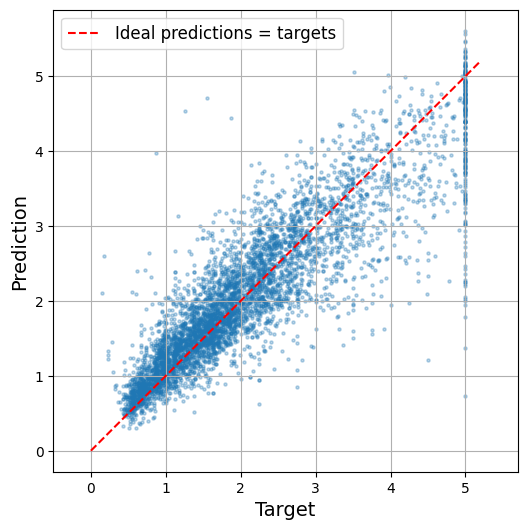

In [16]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, s=5, alpha=0.3)
plt.plot([0, 5.2], [0, 5.2], color='red', linestyle='--',
         label="Ideal predictions = targets")
plt.axis("equal")
plt.xlabel("Target")
plt.ylabel("Prediction")
plt.legend(fontsize=12)
plt.grid()

plt.show()

In [17]:
from sklearn.datasets import fetch_openml

fashion_mnist = fetch_openml(name="Fashion-MNIST", as_frame=False)
targets = fashion_mnist.target.astype(int)

In [18]:
X_train, y_train = fashion_mnist.data[:60_000], targets[:60_000]
X_test, y_test = fashion_mnist.data[60_000:], targets[60_000:]

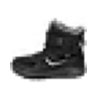

In [22]:
X_sample = X_train[0].reshape(28, 28)  # first image in the training set
plt.figure(figsize=(1,1))  # extra code – reduce the figure size
plt.imshow(X_sample, cmap="binary")
plt.axis('off')  # extra code – remove the axis
plt.show()

In [23]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

In [24]:
class_names[y_train[0]]

'Ankle boot'

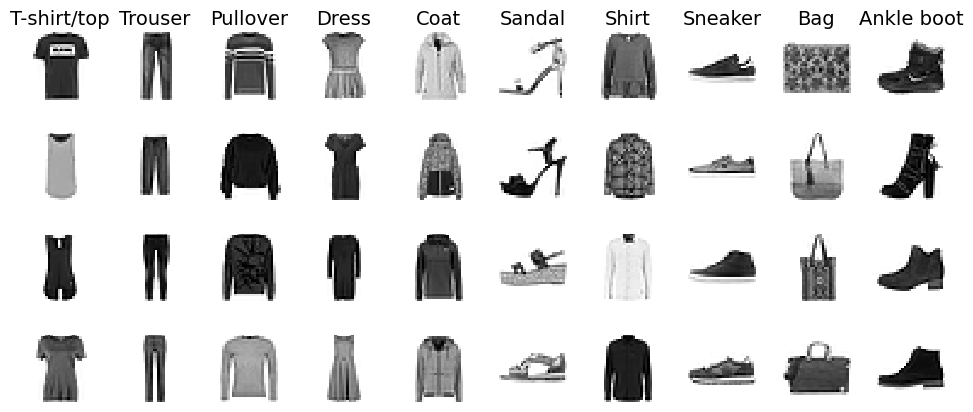

In [25]:
# extra code – this cell generates Figure 9–10
n_rows = 4
plt.figure(figsize=(12, n_rows * 1.2))
for row in range(n_rows):
    for class_index in range(10):
        X_img = X_train[y_train==class_index][row].reshape(28, 28)
        y_img = y_train[y_train==class_index][row]
        plt.subplot(n_rows, 10, 10 * row + class_index + 1)
        plt.imshow(X_img, cmap="binary", interpolation="nearest")
        plt.axis('off')
        if row == 0:
            plt.title(class_names[y_img])
plt.subplots_adjust(wspace=0.2, hspace=0.5)

plt.show()

In [26]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import MinMaxScaler

mlp_clf = MLPClassifier(hidden_layer_sizes=[200, 100], verbose=True,
                        early_stopping=True, random_state=42)
pipeline = make_pipeline(MinMaxScaler(), mlp_clf)
pipeline.fit(X_train, y_train)
accuracy = pipeline.score(X_test, y_test)

Iteration 1, loss = 0.57483807
Validation score: 0.849333
Iteration 2, loss = 0.39938584
Validation score: 0.856833
Iteration 3, loss = 0.35435272
Validation score: 0.869333
Iteration 4, loss = 0.32570927
Validation score: 0.863833
Iteration 5, loss = 0.30588352
Validation score: 0.874167
Iteration 6, loss = 0.29053832
Validation score: 0.874000
Iteration 7, loss = 0.27455976
Validation score: 0.879333
Iteration 8, loss = 0.26407281
Validation score: 0.878500
Iteration 9, loss = 0.25317835
Validation score: 0.882167
Iteration 10, loss = 0.24414312
Validation score: 0.892833
Iteration 11, loss = 0.23601645
Validation score: 0.890000
Iteration 12, loss = 0.23008384
Validation score: 0.887333
Iteration 13, loss = 0.22123722
Validation score: 0.885167
Iteration 14, loss = 0.21190658
Validation score: 0.879333
Iteration 15, loss = 0.20617121
Validation score: 0.892667
Iteration 16, loss = 0.19935674
Validation score: 0.891667
Iteration 17, loss = 0.19323595
Validation score: 0.891667
Iterat

In [28]:
mlp_clf.classes_      # The 10 class labels

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [29]:
mlp_clf.n_outputs_    # 10 output neurons

10

In [30]:
accuracy

0.8907

In [31]:
mlp_clf.best_validation_score_

0.8965

In [32]:
mlp_clf.score(X_test, y_test)

0.8713

In [33]:
X_new = X_test[:15]  # let's pretend these are 15 new images
mlp_clf.predict(X_new)

array([9, 2, 1, 1, 6, 1, 4, 6, 5, 7, 4, 5, 8, 3, 4])

In [34]:
y_test[:15]

array([9, 2, 1, 1, 6, 1, 4, 6, 5, 7, 4, 5, 7, 3, 4])

In [35]:
y_proba = mlp_clf.predict_proba(X_new)
y_proba[12]

array([0., 0., 0., 0., 0., 0., 0., 0., 1., 0.])

In [36]:
y_proba = mlp_clf.predict_proba(X_test)
(y_proba.max(axis=1) < 0.999).sum()

np.int64(24)

In [37]:
y_proba.max(axis=1)

array([1., 1., 1., ..., 1., 1., 1.], shape=(10000,))

In [38]:
y_proba = mlp_clf.predict_proba(X_test)
sum(y_proba.max(axis=1) < 0.99)

np.int64(16)

Ex #10

In [1]:
import numpy as np
from sklearn.datasets import fetch_covtype

# Load the features and the target labels.
X, y = fetch_covtype(return_X_y=True)

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

# Count how many examples belong to each cover type.
classes, counts = np.unique(y, return_counts=True)

print("\nCover type |   Examples | Share")
for label, count in zip(classes, counts):
    print(f"{label:>10} | {count:>10,} | {count / y.size:>6.2%}")

# Find the class with the most examples.
majority_index = counts.argmax()
majority_class = classes[majority_index]
majority_share = counts[majority_index] / y.size

print(f"\nMost common cover type: {majority_class}")
print(f"Always-guess-that-class accuracy: {majority_share:.2%}")

X shape: (581012, 54)
y shape: (581012,)

Cover type |   Examples | Share
         1 |    211,840 | 36.46%
         2 |    283,301 | 48.76%
         3 |     35,754 |  6.15%
         4 |      2,747 |  0.47%
         5 |      9,493 |  1.63%
         6 |     17,367 |  2.99%
         7 |     20,510 |  3.53%

Most common cover type: 2
Always-guess-that-class accuracy: 48.76%


In [2]:
import numpy as np
from sklearn.model_selection import train_test_split

# Set aside 15% for the final test.
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=42
)

# Take 15% of the original dataset from the remaining 85%.
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.15 / 0.85, stratify=y_dev, random_state=42
)

print(f"{'Split':<12} {'Rows':>9} {'Share':>8} {'Type 4':>9}")
for name, labels in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test),
]:
    print(
        f"{name:<12} {labels.size:>9,} "
        f"{labels.size / y.size:>8.2%} "
        f"{np.sum(labels == 4):>9,}"
    )

# Choose the majority label using the training data.
classes, counts = np.unique(y_train, return_counts=True)
majority_class = classes[counts.argmax()]
val_baseline = np.mean(y_val == majority_class)

print(f"\nTraining majority class: {majority_class}")
print(f"Majority-class validation accuracy: {val_baseline:.2%}")

Split             Rows    Share    Type 4
Train          406,708   70.00%     1,923
Validation      87,152   15.00%       412
Test            87,152   15.00%       412

Training majority class: 2
Majority-class validation accuracy: 48.76%


In [4]:
import pandas as pd
from IPython.display import display
from sklearn.datasets import fetch_covtype

# Get the official feature names from the dataset you already loaded.
feature_names = fetch_covtype(download_if_missing=False).feature_names

sample_columns = [f"Sample {i}" for i in range(1, len(rows) + 1)]
actual_cover_types = [cover_type_names[label] for label in y_train[rows]]

print("Actual cover type for each sample")
display(pd.DataFrame(
    [actual_cover_types],
    index=["Actual cover type"],
    columns=sample_columns,
))

feature_profiles = pd.DataFrame(
    X_train[rows].astype(int).T,
    index=feature_names,
    columns=sample_columns,
)
feature_profiles.index.name = "Input feature"

print(f"All {len(feature_names)} input features")
with pd.option_context("display.max_rows", None):
    display(feature_profiles)

Actual cover type for each sample


,Sample 1,Sample 2,Sample 3
Actual cover type,Lodgepole Pine,Krummholz,Spruce/Fir


All 54 input features


,Sample 1,Sample 2,Sample 3
Input feature,,,
Elevation,2581,3379,3297
Aspect,324,74,261
Slope,22,10,9
Horizontal_Distance_To_Hydrology,124,212,306
Vertical_Distance_To_Hydrology,47,5,49
Horizontal_Distance_To_Roadways,150,2470,3522
Hillshade_9am,158,232,198
Hillshade_Noon,210,222,245
Hillshade_3pm,188,122,186


In [5]:
from sklearn.metrics import accuracy_score, classification_report
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

baseline_mlp = make_pipeline(
    StandardScaler(),
    MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        learning_rate_init=0.001,
        batch_size=256,
        alpha=0.0001,
        max_iter=30,
        random_state=42,
        verbose=True,
    ),
)

baseline_mlp.fit(X_train, y_train)

train_predictions = baseline_mlp.predict(X_train)
val_predictions = baseline_mlp.predict(X_val)

train_accuracy = accuracy_score(y_train, train_predictions)
val_accuracy = accuracy_score(y_val, val_predictions)
mlp = baseline_mlp.named_steps["mlpclassifier"]

print("\nMLP baseline results")
print(f"Epochs completed:                   {mlp.n_iter_}")
print(f"Majority-class validation accuracy: {val_baseline:.2%}")
print(f"MLP training accuracy:              {train_accuracy:.2%}")
print(f"MLP validation accuracy:            {val_accuracy:.2%}")
print(f"Train–validation gap:               {100 * (train_accuracy - val_accuracy):.2f} pp")

labels = sorted(cover_type_names)
print("\nValidation results by cover type")
print(classification_report(
    y_val,
    val_predictions,
    labels=labels,
    target_names=[cover_type_names[label] for label in labels],
    digits=3,
    zero_division=0,
))

Iteration 1, loss = 0.63204078
Iteration 2, loss = 0.52385361
Iteration 3, loss = 0.48615847
Iteration 4, loss = 0.46175478
Iteration 5, loss = 0.44314541
Iteration 6, loss = 0.42960014
Iteration 7, loss = 0.41917624
Iteration 8, loss = 0.41147508
Iteration 9, loss = 0.40431089
Iteration 10, loss = 0.39787602
Iteration 11, loss = 0.39193746
Iteration 12, loss = 0.38672556
Iteration 13, loss = 0.38225929
Iteration 14, loss = 0.37862078
Iteration 15, loss = 0.37453174
Iteration 16, loss = 0.37132912
Iteration 17, loss = 0.36846989
Iteration 18, loss = 0.36559333
Iteration 19, loss = 0.36310380
Iteration 20, loss = 0.36024131
Iteration 21, loss = 0.35809874
Iteration 22, loss = 0.35704381
Iteration 23, loss = 0.35446173
Iteration 24, loss = 0.35244205
Iteration 25, loss = 0.35063885
Iteration 26, loss = 0.34881786
Iteration 27, loss = 0.34701880
Iteration 28, loss = 0.34504838
Iteration 29, loss = 0.34394506
Iteration 30, loss = 0.34207717


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(



MLP baseline results
Epochs completed:                   30
Majority-class validation accuracy: 48.76%
MLP training accuracy:              86.13%
MLP validation accuracy:            85.70%
Train–validation gap:               0.44 pp

Validation results by cover type
                   precision    recall  f1-score   support

       Spruce/Fir      0.869     0.838     0.853     31776
   Lodgepole Pine      0.869     0.890     0.879     42495
   Ponderosa Pine      0.823     0.862     0.842      5363
Cottonwood/Willow      0.827     0.650     0.728       412
            Aspen      0.608     0.649     0.628      1424
      Douglas-fir      0.698     0.683     0.691      2605
        Krummholz      0.883     0.859     0.871      3077

         accuracy                          0.857     87152
        macro avg      0.797     0.776     0.785     87152
     weighted avg      0.857     0.857     0.857     87152



In [6]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score, recall_score

longer_mlp = clone(baseline_mlp).set_params(mlpclassifier__max_iter=60)
longer_mlp.fit(X_train, y_train)

longer_train_accuracy = longer_mlp.score(X_train, y_train)
longer_val_predictions = longer_mlp.predict(X_val)
longer_val_accuracy = accuracy_score(y_val, longer_val_predictions)
longer_mlp_step = longer_mlp.named_steps["mlpclassifier"]

print(f"\n{'Metric':<27} {'30-epoch cap':>13} {'60-epoch cap':>13}")
print(f"{'Epochs completed':<27} {mlp.n_iter_:>13} {longer_mlp_step.n_iter_:>13}")
print(f"{'Final training loss':<27} {mlp.loss_:>13.4f} {longer_mlp_step.loss_:>13.4f}")
print(f"{'Training accuracy':<27} {train_accuracy:>13.2%} {longer_train_accuracy:>13.2%}")
print(f"{'Validation accuracy':<27} {val_accuracy:>13.2%} {longer_val_accuracy:>13.2%}")

baseline_macro_recall = recall_score(y_val, val_predictions, average="macro")
longer_macro_recall = recall_score(y_val, longer_val_predictions, average="macro")
print(f"{'Validation macro recall':<27} {baseline_macro_recall:>13.2%} {longer_macro_recall:>13.2%}")

Iteration 1, loss = 0.63204078
Iteration 2, loss = 0.52385361
Iteration 3, loss = 0.48615847
Iteration 4, loss = 0.46175478
Iteration 5, loss = 0.44314541
Iteration 6, loss = 0.42960014
Iteration 7, loss = 0.41917624
Iteration 8, loss = 0.41147508
Iteration 9, loss = 0.40431089
Iteration 10, loss = 0.39787602
Iteration 11, loss = 0.39193746
Iteration 12, loss = 0.38672556
Iteration 13, loss = 0.38225929
Iteration 14, loss = 0.37862078
Iteration 15, loss = 0.37453174
Iteration 16, loss = 0.37132912
Iteration 17, loss = 0.36846989
Iteration 18, loss = 0.36559333
Iteration 19, loss = 0.36310380
Iteration 20, loss = 0.36024131
Iteration 21, loss = 0.35809874
Iteration 22, loss = 0.35704381
Iteration 23, loss = 0.35446173
Iteration 24, loss = 0.35244205
Iteration 25, loss = 0.35063885
Iteration 26, loss = 0.34881786
Iteration 27, loss = 0.34701880
Iteration 28, loss = 0.34504838
Iteration 29, loss = 0.34394506
Iteration 30, loss = 0.34207717
Iteration 31, loss = 0.34063688
Iteration 32, los

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(



Metric                       30-epoch cap  60-epoch cap
Epochs completed                       30            60
Final training loss                0.3421        0.3122
Training accuracy                  86.13%        86.90%
Validation accuracy                85.70%        86.48%
Validation macro recall            77.60%        75.92%


In [7]:
from sklearn.base import clone
from sklearn.metrics import recall_score

wider_mlp = clone(longer_mlp).set_params(
    mlpclassifier__hidden_layer_sizes=(128, 32)
)
wider_mlp.fit(X_train, y_train)

wider_train_accuracy = wider_mlp.score(X_train, y_train)
wider_val_predictions = wider_mlp.predict(X_val)
wider_val_accuracy = (wider_val_predictions == y_val).mean()

labels = sorted(cover_type_names)
recall_30 = recall_score(y_val, val_predictions, labels=labels, average=None)
recall_60 = recall_score(y_val, longer_val_predictions, labels=labels, average=None)
recall_wider = recall_score(y_val, wider_val_predictions, labels=labels, average=None)

print(f"\n{'Metric':<24} {'64 → 32':>10} {'128 → 32':>10}")
print(f"{'Training accuracy':<24} {longer_train_accuracy:>10.2%} {wider_train_accuracy:>10.2%}")
print(f"{'Validation accuracy':<24} {longer_val_accuracy:>10.2%} {wider_val_accuracy:>10.2%}")
print(f"{'Validation macro recall':<24} {recall_60.mean():>10.2%} {recall_wider.mean():>10.2%}")

print("\nValidation recall by cover type")
print(f"{'Cover type':<20} {'30 epochs':>10} {'60 epochs':>10} {'Wider, 60':>10}")
for label, r30, r60, rwide in zip(labels, recall_30, recall_60, recall_wider):
    print(f"{cover_type_names[label]:<20} {r30:>10.2%} {r60:>10.2%} {rwide:>10.2%}")

Iteration 1, loss = 0.60777923
Iteration 2, loss = 0.48608948
Iteration 3, loss = 0.44600676
Iteration 4, loss = 0.42088111
Iteration 5, loss = 0.40198697
Iteration 6, loss = 0.38674300
Iteration 7, loss = 0.37531813
Iteration 8, loss = 0.36547943
Iteration 9, loss = 0.35694656
Iteration 10, loss = 0.34978300
Iteration 11, loss = 0.34296981
Iteration 12, loss = 0.33699095
Iteration 13, loss = 0.33223521
Iteration 14, loss = 0.32782849
Iteration 15, loss = 0.32331149
Iteration 16, loss = 0.31949726
Iteration 17, loss = 0.31596341
Iteration 18, loss = 0.31229893
Iteration 19, loss = 0.30954771
Iteration 20, loss = 0.30698283
Iteration 21, loss = 0.30352632
Iteration 22, loss = 0.30095795
Iteration 23, loss = 0.29941468
Iteration 24, loss = 0.29703136
Iteration 25, loss = 0.29466112
Iteration 26, loss = 0.29285143
Iteration 27, loss = 0.29118360
Iteration 28, loss = 0.28906073
Iteration 29, loss = 0.28735567
Iteration 30, loss = 0.28561579
Iteration 31, loss = 0.28373638
Iteration 32, los

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(



Metric                      64 → 32   128 → 32
Training accuracy            86.90%     90.12%
Validation accuracy          86.48%     89.49%
Validation macro recall      75.92%     82.11%

Validation recall by cover type
Cover type            30 epochs  60 epochs  Wider, 60
Spruce/Fir               83.79%     79.27%     89.44%
Lodgepole Pine           89.01%     94.27%     91.55%
Ponderosa Pine           86.20%     88.89%     89.39%
Cottonwood/Willow        65.05%     68.20%     76.70%
Aspen                    64.89%     48.74%     66.71%
Douglas-fir              68.33%     64.61%     72.71%
Krummholz                85.93%     87.49%     88.27%


In [8]:
from sklearn.base import clone
from sklearn.metrics import recall_score

wider_second_mlp = clone(wider_mlp).set_params(
    mlpclassifier__hidden_layer_sizes=(128, 64)
)
wider_second_mlp.fit(X_train, y_train)

second_train_accuracy = wider_second_mlp.score(X_train, y_train)
second_val_predictions = wider_second_mlp.predict(X_val)
second_val_accuracy = (second_val_predictions == y_val).mean()

labels = sorted(cover_type_names)
reference_recall = recall_score(
    y_val, wider_val_predictions, labels=labels, average=None
)
second_recall = recall_score(
    y_val, second_val_predictions, labels=labels, average=None
)

print(f"\n{'Metric':<24} {'128 → 32':>10} {'128 → 64':>10}")
print(f"{'Training accuracy':<24} {wider_train_accuracy:>10.2%} {second_train_accuracy:>10.2%}")
print(f"{'Validation accuracy':<24} {wider_val_accuracy:>10.2%} {second_val_accuracy:>10.2%}")
print(f"{'Validation macro recall':<24} {reference_recall.mean():>10.2%} {second_recall.mean():>10.2%}")

print("\nValidation recall by cover type")
print(f"{'Cover type':<20} {'128 → 32':>10} {'128 → 64':>10}")
for label, old_recall, new_recall in zip(labels, reference_recall, second_recall):
    print(f"{cover_type_names[label]:<20} {old_recall:>10.2%} {new_recall:>10.2%}")

Iteration 1, loss = 0.58509025
Iteration 2, loss = 0.47268385
Iteration 3, loss = 0.42847317
Iteration 4, loss = 0.40029925
Iteration 5, loss = 0.37970680
Iteration 6, loss = 0.36394988
Iteration 7, loss = 0.35131365
Iteration 8, loss = 0.34059661
Iteration 9, loss = 0.33193354
Iteration 10, loss = 0.32307855
Iteration 11, loss = 0.31717812
Iteration 12, loss = 0.31027502
Iteration 13, loss = 0.30542633
Iteration 14, loss = 0.30066435
Iteration 15, loss = 0.29538240
Iteration 16, loss = 0.29221168
Iteration 17, loss = 0.28728833
Iteration 18, loss = 0.28303026
Iteration 19, loss = 0.28003499
Iteration 20, loss = 0.27685888
Iteration 21, loss = 0.27413855
Iteration 22, loss = 0.27053554
Iteration 23, loss = 0.26765135
Iteration 24, loss = 0.26534274
Iteration 25, loss = 0.26324405
Iteration 26, loss = 0.26134188
Iteration 27, loss = 0.25920914
Iteration 28, loss = 0.25745933
Iteration 29, loss = 0.25597951
Iteration 30, loss = 0.25326691
Iteration 31, loss = 0.25136725
Iteration 32, los

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(



Metric                     128 → 32   128 → 64
Training accuracy            90.12%     91.53%
Validation accuracy          89.49%     90.72%
Validation macro recall      82.11%     86.17%

Validation recall by cover type
Cover type             128 → 32   128 → 64
Spruce/Fir               89.44%     87.22%
Lodgepole Pine           91.55%     94.25%
Ponderosa Pine           89.39%     91.72%
Cottonwood/Willow        76.70%     79.85%
Aspen                    66.71%     76.97%
Douglas-fir              72.71%     79.96%
Krummholz                88.27%     93.24%


In [9]:
from sklearn.base import clone
from sklearn.metrics import recall_score

longer_wide_mlp = clone(wider_second_mlp).set_params(
    mlpclassifier__max_iter=120,
    mlpclassifier__verbose=False,
)
longer_wide_mlp.fit(X_train, y_train)

reference_step = wider_second_mlp.named_steps["mlpclassifier"]
longer_step = longer_wide_mlp.named_steps["mlpclassifier"]
longer_wide_predictions = longer_wide_mlp.predict(X_val)

labels = sorted(cover_type_names)
longer_recall = recall_score(
    y_val, longer_wide_predictions, labels=labels, average=None
)

print(f"{'Metric':<27} {'60-epoch cap':>14} {'120-epoch cap':>14}")
print(f"{'Epochs completed':<27} {reference_step.n_iter_:>14} {longer_step.n_iter_:>14}")
print(f"{'Final training loss':<27} {reference_step.loss_:>14.4f} {longer_step.loss_:>14.4f}")
print(f"{'Training accuracy':<27} {second_train_accuracy:>14.2%} {longer_wide_mlp.score(X_train, y_train):>14.2%}")
print(f"{'Validation accuracy':<27} {second_val_accuracy:>14.2%} {(longer_wide_predictions == y_val).mean():>14.2%}")
print(f"{'Validation macro recall':<27} {second_recall.mean():>14.2%} {longer_recall.mean():>14.2%}")

print("\nValidation recall by cover type")
for label, old, new in zip(labels, second_recall, longer_recall):
    print(f"{cover_type_names[label]:<20} {old:>7.2%} → {new:>7.2%} ({100 * (new - old):+.2f} pp)")

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (120) reached and the optimization hasn't converged yet.
  warnings.warn(


Metric                        60-epoch cap  120-epoch cap
Epochs completed                        60            120
Final training loss                 0.2209         0.1941
Training accuracy                   91.53%         92.05%
Validation accuracy                 90.72%         91.19%
Validation macro recall             86.17%         85.87%

Validation recall by cover type
Spruce/Fir            87.22% →  86.51% (-0.71 pp)
Lodgepole Pine        94.25% →  95.79% (+1.54 pp)
Ponderosa Pine        91.72% →  90.47% (-1.25 pp)
Cottonwood/Willow     79.85% →  79.13% (-0.73 pp)
Aspen                 76.97% →  70.15% (-6.81 pp)
Douglas-fir           79.96% →  86.22% (+6.26 pp)
Krummholz             93.24% →  92.82% (-0.42 pp)


In [10]:
from sklearn.base import clone
from sklearn.metrics import recall_score

wider_first_mlp = clone(longer_wide_mlp).set_params(
    mlpclassifier__hidden_layer_sizes=(256, 64),
    mlpclassifier__verbose=True,
)
wider_first_mlp.fit(X_train, y_train)

new_predictions = wider_first_mlp.predict(X_val)
labels = sorted(cover_type_names)
new_recall = recall_score(
    y_val, new_predictions, labels=labels, average=None
)

old_step = longer_wide_mlp.named_steps["mlpclassifier"]
new_step = wider_first_mlp.named_steps["mlpclassifier"]

print(f"\n{'Metric':<25} {'128 → 64':>12} {'256 → 64':>12}")
print(f"{'Epochs completed':<25} {old_step.n_iter_:>12} {new_step.n_iter_:>12}")
print(f"{'Final training loss':<25} {old_step.loss_:>12.4f} {new_step.loss_:>12.4f}")
print(f"{'Training accuracy':<25} {longer_wide_mlp.score(X_train, y_train):>12.2%} {wider_first_mlp.score(X_train, y_train):>12.2%}")
print(f"{'Validation accuracy':<25} {(longer_wide_predictions == y_val).mean():>12.2%} {(new_predictions == y_val).mean():>12.2%}")
print(f"{'Validation macro recall':<25} {longer_recall.mean():>12.2%} {new_recall.mean():>12.2%}")

print("\nValidation recall by cover type")
for label, old, new in zip(labels, longer_recall, new_recall):
    print(f"{cover_type_names[label]:<20} {old:>7.2%} → {new:>7.2%}")

Iteration 1, loss = 0.56799844
Iteration 2, loss = 0.45305339
Iteration 3, loss = 0.40600190
Iteration 4, loss = 0.37395772
Iteration 5, loss = 0.35251210
Iteration 6, loss = 0.33472280
Iteration 7, loss = 0.32161128
Iteration 8, loss = 0.31040373
Iteration 9, loss = 0.29978817
Iteration 10, loss = 0.29225639
Iteration 11, loss = 0.28510525
Iteration 12, loss = 0.27756339
Iteration 13, loss = 0.27173631
Iteration 14, loss = 0.26654547
Iteration 15, loss = 0.26091678
Iteration 16, loss = 0.25805001
Iteration 17, loss = 0.25274900
Iteration 18, loss = 0.25027157
Iteration 19, loss = 0.24606849
Iteration 20, loss = 0.24325928
Iteration 21, loss = 0.24100423
Iteration 22, loss = 0.23751945
Iteration 23, loss = 0.23438576
Iteration 24, loss = 0.23170364
Iteration 25, loss = 0.22982058
Iteration 26, loss = 0.22714098
Iteration 27, loss = 0.22503167
Iteration 28, loss = 0.22311271
Iteration 29, loss = 0.22183183
Iteration 30, loss = 0.21906280
Iteration 31, loss = 0.21762170
Iteration 32, los

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (120) reached and the optimization hasn't converged yet.
  warnings.warn(



Metric                        128 → 64     256 → 64
Epochs completed                   120          120
Final training loss             0.1941       0.1571
Training accuracy               92.05%       93.83%
Validation accuracy             91.19%       92.88%
Validation macro recall         85.87%       89.42%

Validation recall by cover type
Spruce/Fir            86.51% →  91.44%
Lodgepole Pine        95.79% →  94.72%
Ponderosa Pine        90.47% →  95.56%
Cottonwood/Willow     79.13% →  85.44%
Aspen                 70.15% →  86.80%
Douglas-fir           86.22% →  76.08%
Krummholz             92.82% →  95.87%


In [11]:
from sklearn.base import clone
from sklearn.metrics import recall_score

wider_both_mlp = clone(wider_first_mlp).set_params(
    mlpclassifier__hidden_layer_sizes=(256, 128)
)
wider_both_mlp.fit(X_train, y_train)

candidate_predictions = wider_both_mlp.predict(X_val)
labels = sorted(cover_type_names)
candidate_recall = recall_score(
    y_val, candidate_predictions, labels=labels, average=None
)

reference_step = wider_first_mlp.named_steps["mlpclassifier"]
candidate_step = wider_both_mlp.named_steps["mlpclassifier"]

metrics = [
    ("Epochs completed", reference_step.n_iter_, candidate_step.n_iter_, "d"),
    ("Final training loss", reference_step.loss_, candidate_step.loss_, ".4f"),
    ("Training accuracy",
     wider_first_mlp.score(X_train, y_train),
     wider_both_mlp.score(X_train, y_train), ".2%"),
    ("Validation accuracy",
     (new_predictions == y_val).mean(),
     (candidate_predictions == y_val).mean(), ".2%"),
    ("Validation macro recall", new_recall.mean(), candidate_recall.mean(), ".2%"),
]

print(f"\n{'Metric':<25} {'256 → 64':>12} {'256 → 128':>12}")
for name, reference, candidate, fmt in metrics:
    print(f"{name:<25} {reference:>12{fmt}} {candidate:>12{fmt}}")

print("\nValidation recall by cover type")
for label, reference, candidate in zip(labels, new_recall, candidate_recall):
    print(
        f"{cover_type_names[label]:<20} "
        f"{reference:>7.2%} → {candidate:>7.2%} "
        f"({100 * (candidate - reference):+.2f} pp)"
    )

Iteration 1, loss = 0.55706702
Iteration 2, loss = 0.43598094
Iteration 3, loss = 0.38032777
Iteration 4, loss = 0.34696901
Iteration 5, loss = 0.32239686
Iteration 6, loss = 0.30464092
Iteration 7, loss = 0.29095654
Iteration 8, loss = 0.27847245
Iteration 9, loss = 0.26959532
Iteration 10, loss = 0.26108003
Iteration 11, loss = 0.25377159
Iteration 12, loss = 0.24817178
Iteration 13, loss = 0.24070090
Iteration 14, loss = 0.23652852
Iteration 15, loss = 0.23105927
Iteration 16, loss = 0.22719812
Iteration 17, loss = 0.22316351
Iteration 18, loss = 0.21892852
Iteration 19, loss = 0.21722666
Iteration 20, loss = 0.21275320
Iteration 21, loss = 0.20953968
Iteration 22, loss = 0.20670091
Iteration 23, loss = 0.20439251
Iteration 24, loss = 0.20236064
Iteration 25, loss = 0.19917244
Iteration 26, loss = 0.19649391
Iteration 27, loss = 0.19475307
Iteration 28, loss = 0.19288432
Iteration 29, loss = 0.19040202
Iteration 30, loss = 0.18894674
Iteration 31, loss = 0.18772522
Iteration 32, los

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (120) reached and the optimization hasn't converged yet.
  warnings.warn(



Metric                        256 → 64    256 → 128
Epochs completed                   120          120
Final training loss             0.1571       0.1306
Training accuracy               93.83%       95.30%
Validation accuracy             92.88%       94.12%
Validation macro recall         89.42%       89.85%

Validation recall by cover type
Spruce/Fir            91.44% →  94.79% (+3.35 pp)
Lodgepole Pine        94.72% →  94.49% (-0.23 pp)
Ponderosa Pine        95.56% →  94.11% (-1.45 pp)
Cottonwood/Willow     85.44% →  77.91% (-7.52 pp)
Aspen                 86.80% →  86.80% (+0.00 pp)
Douglas-fir           76.08% →  87.26% (+11.17 pp)
Krummholz             95.87% →  93.60% (-2.27 pp)


In [12]:
from sklearn.metrics import accuracy_score, classification_report

final_model = wider_both_mlp
test_predictions = final_model.predict(X_test)
test_accuracy = accuracy_score(y_test, test_predictions)
selected_val_accuracy = accuracy_score(y_val, candidate_predictions)

print(f"Selected model:          (256, 128)")
print(f"Validation accuracy:     {selected_val_accuracy:.2%}")
print(f"Test accuracy:           {test_accuracy:.4%}")
print(f"Above 93% test accuracy: {'Yes' if test_accuracy > 0.93 else 'No'}")

labels = sorted(cover_type_names)
print("\nTest results by cover type")
print(classification_report(
    y_test,
    test_predictions,
    labels=labels,
    target_names=[cover_type_names[label] for label in labels],
    digits=3,
    zero_division=0,
))

Selected model:          (256, 128)
Validation accuracy:     94.12%
Test accuracy:           93.9611%
Above 93% test accuracy: Yes

Test results by cover type
                   precision    recall  f1-score   support

       Spruce/Fir      0.928     0.948     0.938     31776
   Lodgepole Pine      0.955     0.942     0.949     42495
   Ponderosa Pine      0.932     0.946     0.939      5363
Cottonwood/Willow      0.899     0.757     0.822       412
            Aspen      0.827     0.850     0.839      1424
      Douglas-fir      0.907     0.866     0.886      2605
        Krummholz      0.948     0.936     0.942      3077

         accuracy                          0.940     87152
        macro avg      0.914     0.892     0.902     87152
     weighted avg      0.940     0.940     0.940     87152



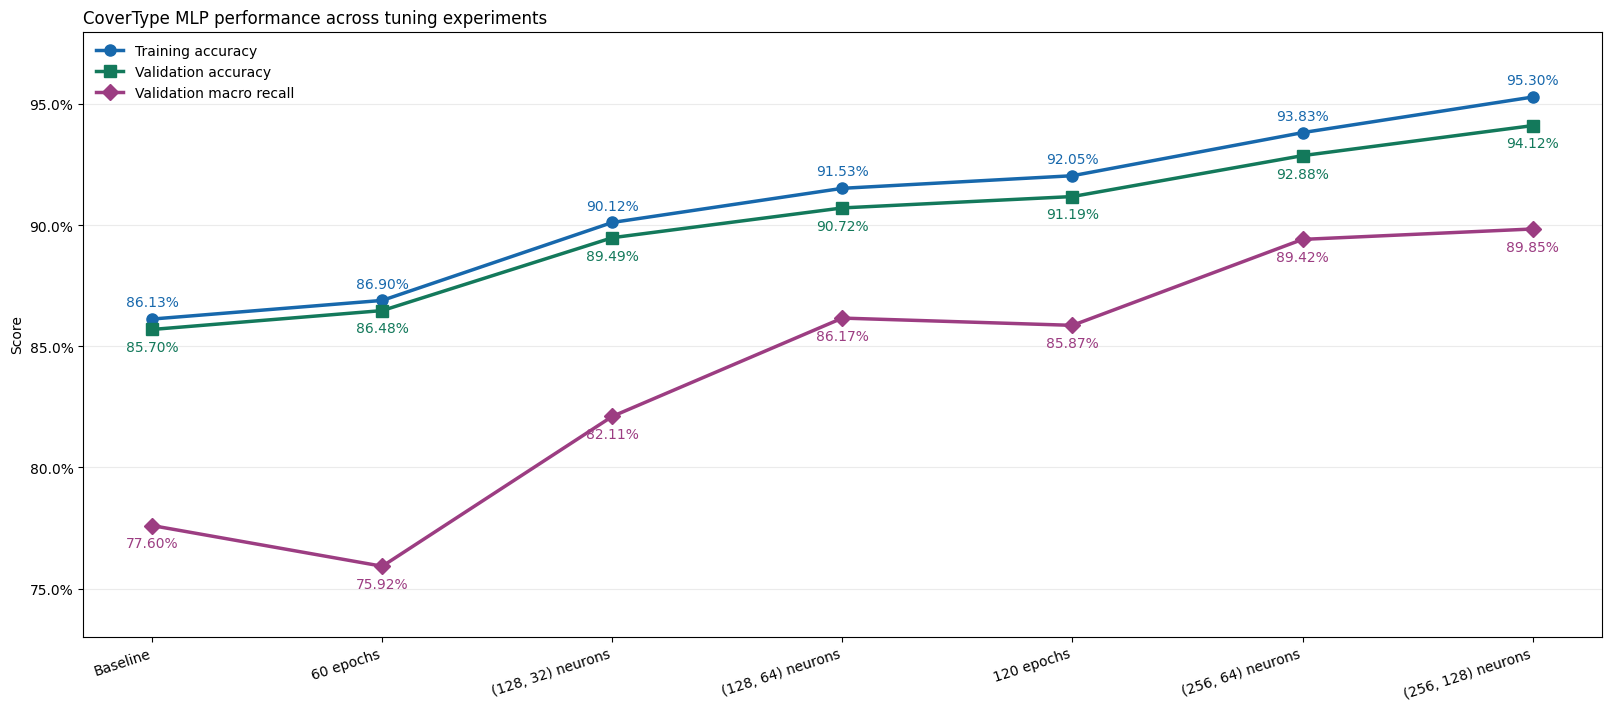

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

experiment_labels = [
    "Baseline",
    "60 epochs",
    "(128, 32) neurons",
    "(128, 64) neurons",
    "120 epochs",
    "(256, 64) neurons",
    "(256, 128) neurons",
]

train_accuracy_pct = np.array([86.13, 86.90, 90.12, 91.53, 92.05, 93.83, 95.30])
val_accuracy_pct = np.array([85.70, 86.48, 89.49, 90.72, 91.19, 92.88, 94.12])
val_macro_recall_pct = np.array([77.60, 75.92, 82.11, 86.17, 85.87, 89.42, 89.85])

x = np.arange(len(experiment_labels))
figure_size = (16, 7)
best_index = int(np.argmax(val_accuracy_pct))

fig, ax = plt.subplots(figsize=figure_size, layout="constrained")

for name, values, color, marker, offset in [
    ("Training accuracy", train_accuracy_pct, "#1768AC", "o", 9),
    ("Validation accuracy", val_accuracy_pct, "#13795B", "s", -16),
    ("Validation macro recall", val_macro_recall_pct, "#9C3D82", "D", -16),
]:
    ax.plot(
        x, values, label=name, color=color,
        marker=marker, linewidth=2.5, markersize=8,
    )
    for i, value in enumerate(values):
        ax.annotate(
            f"{value:.2f}%", (i, value),
            xytext=(0, offset), textcoords="offset points",
            ha="center", color=color, fontsize=10,
        )

ax.set_title("CoverType MLP performance across tuning experiments", loc="left")
ax.set_xticks(x, experiment_labels, rotation=18, ha="right")
ax.set_ylabel("Score")
ax.set_ylim(73, 98)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="upper left", frameon=False)
plt.show()

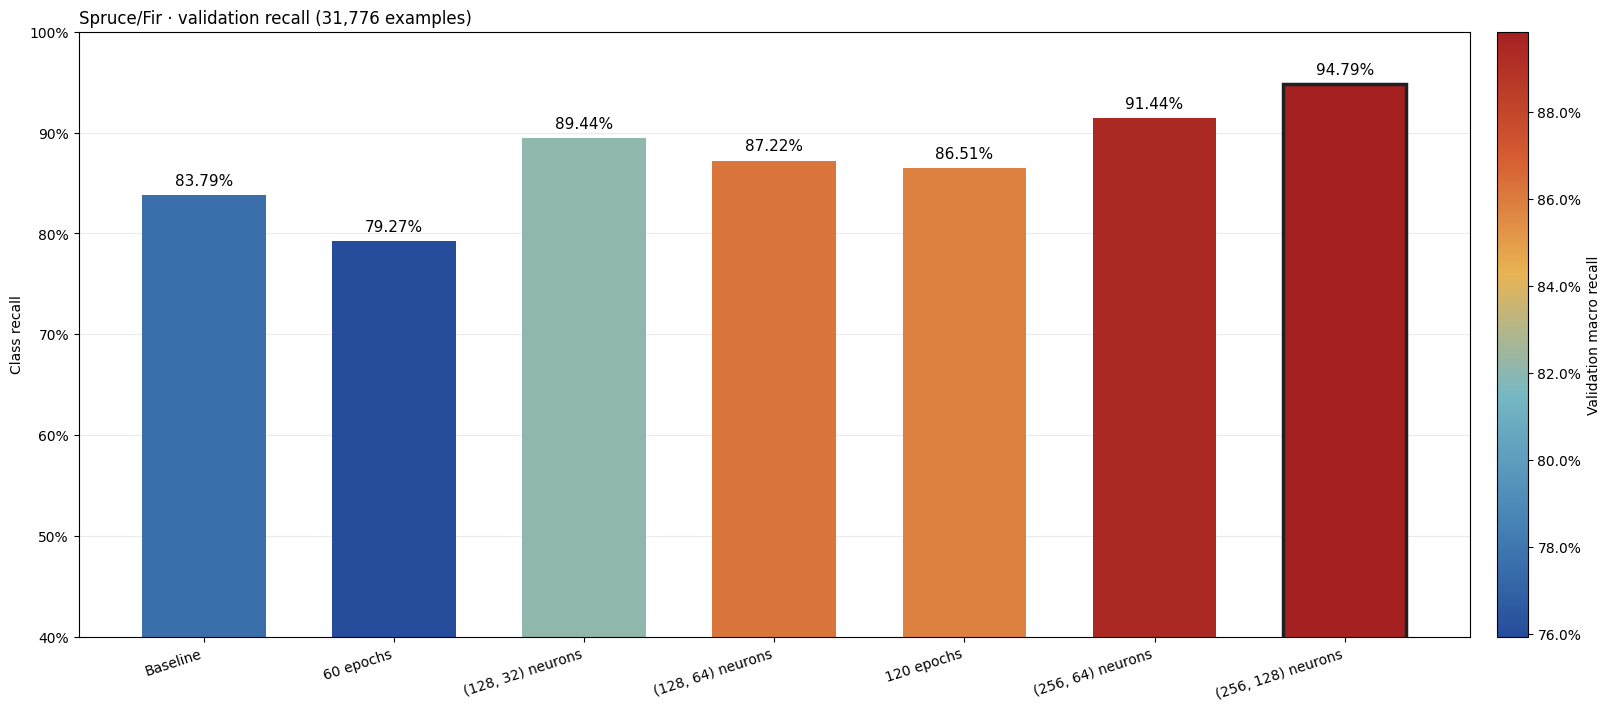

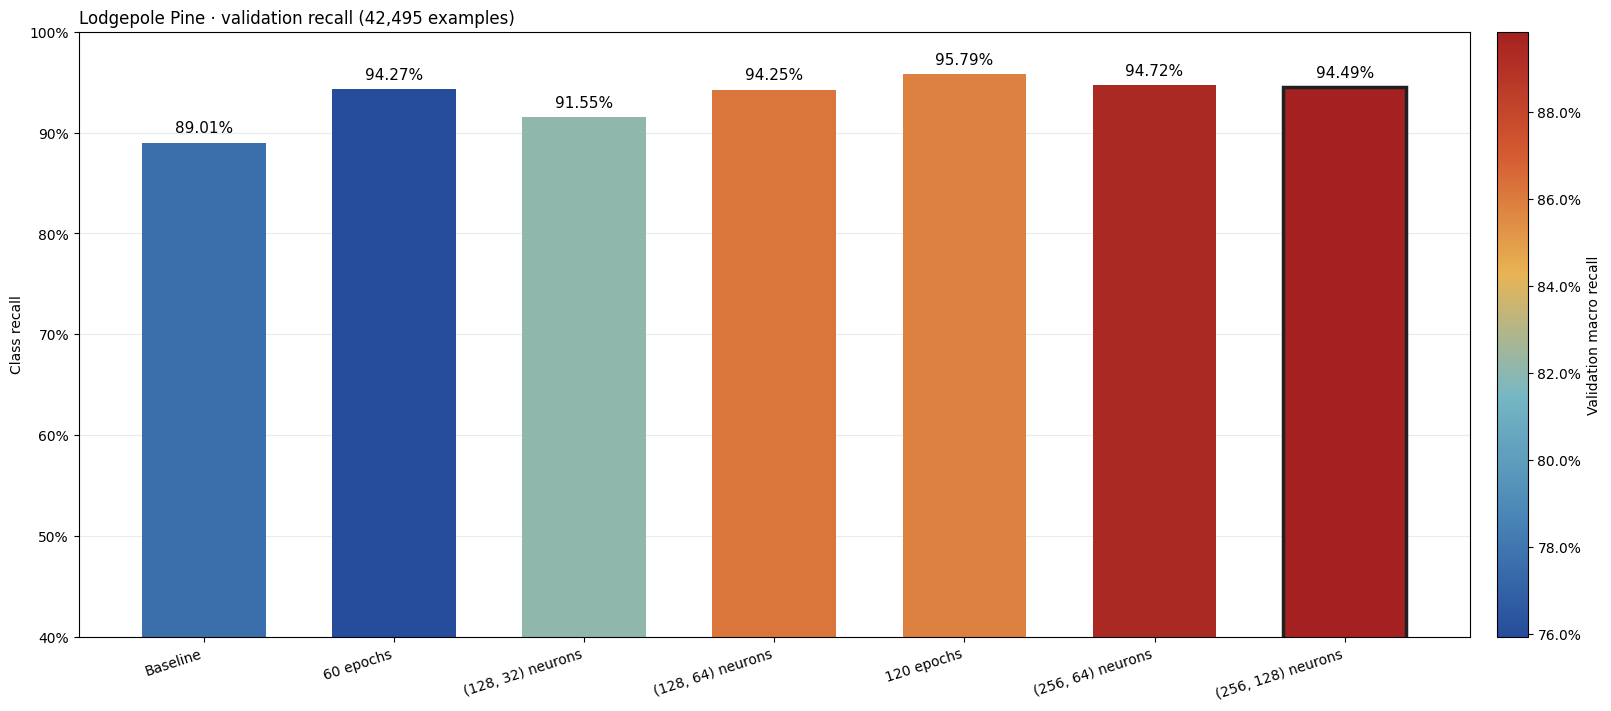

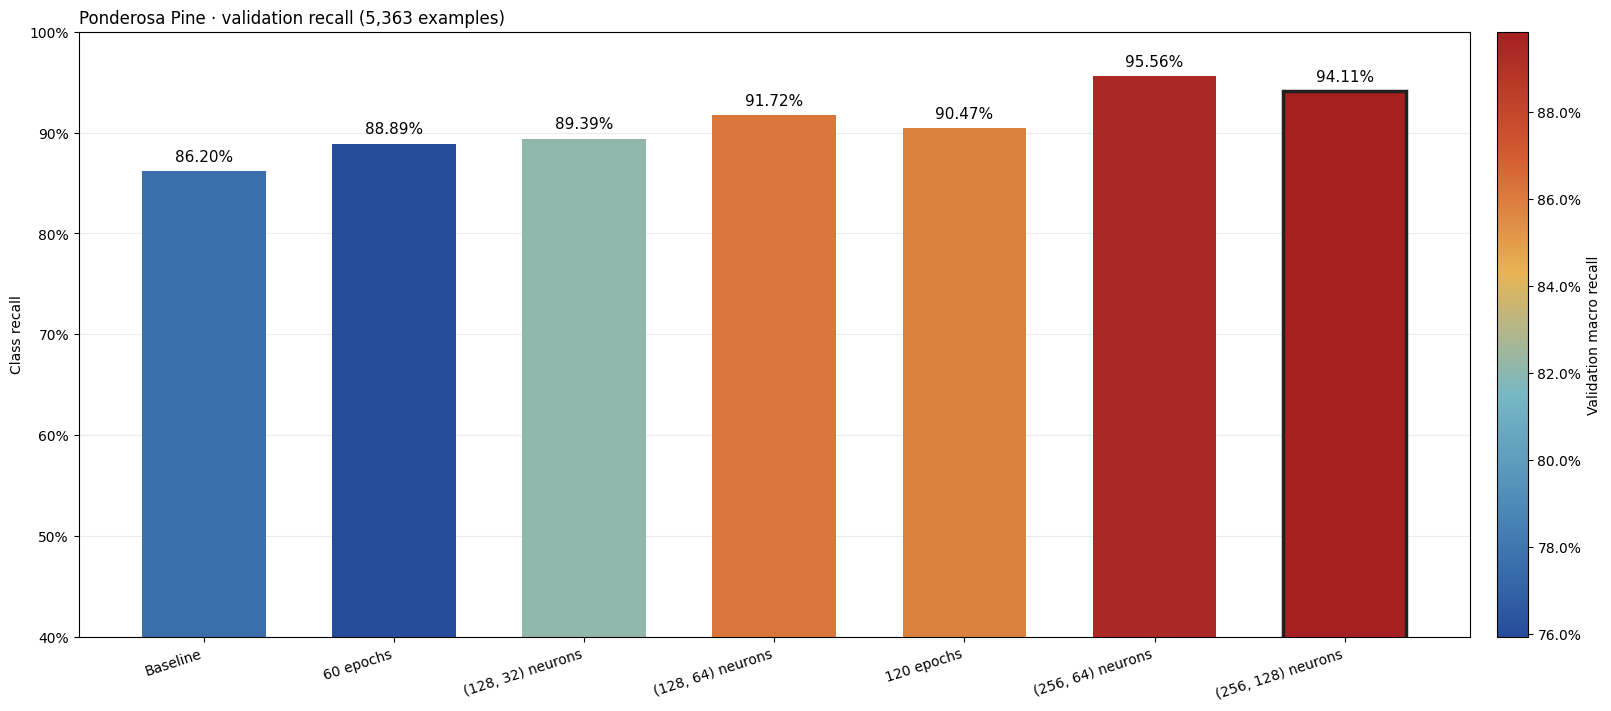

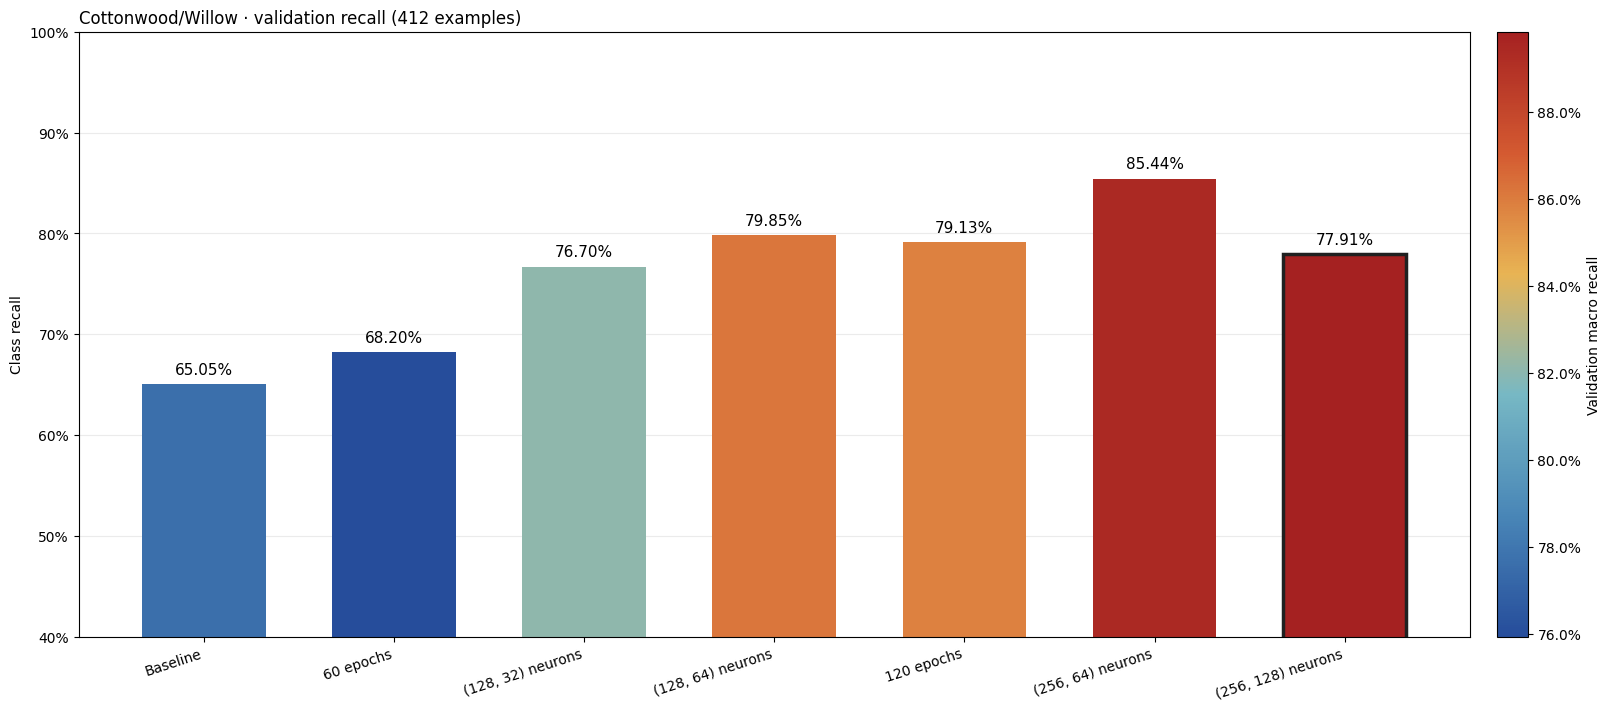

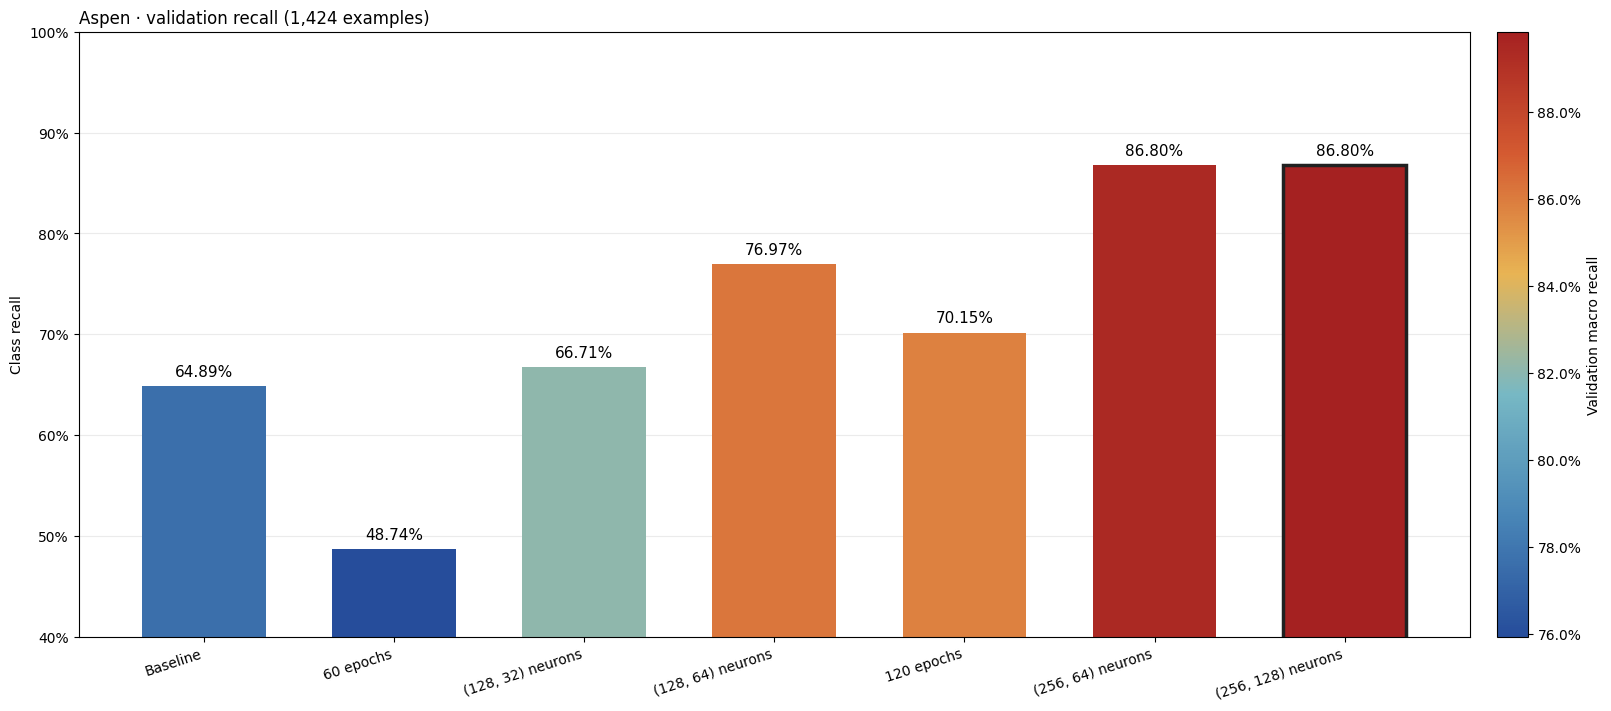

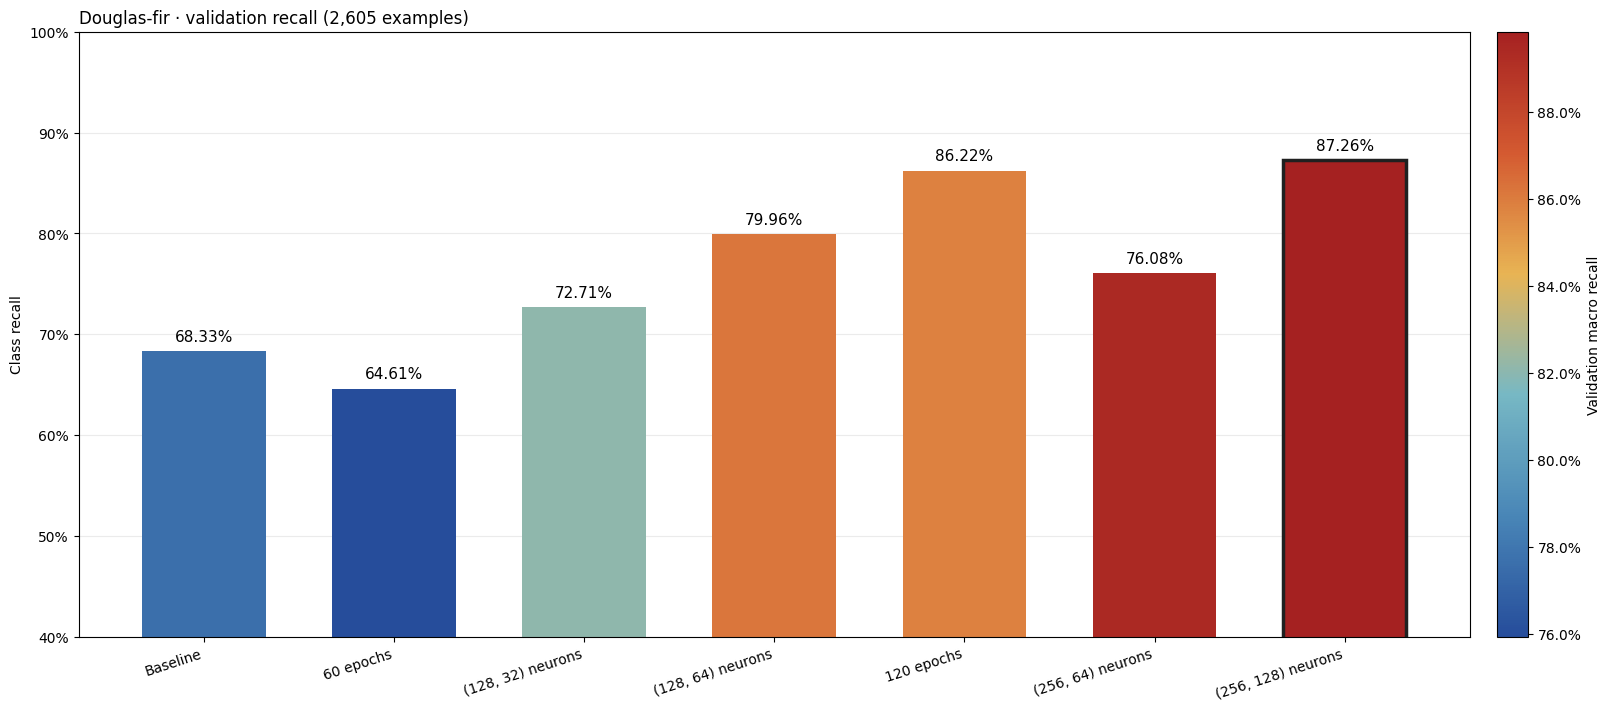

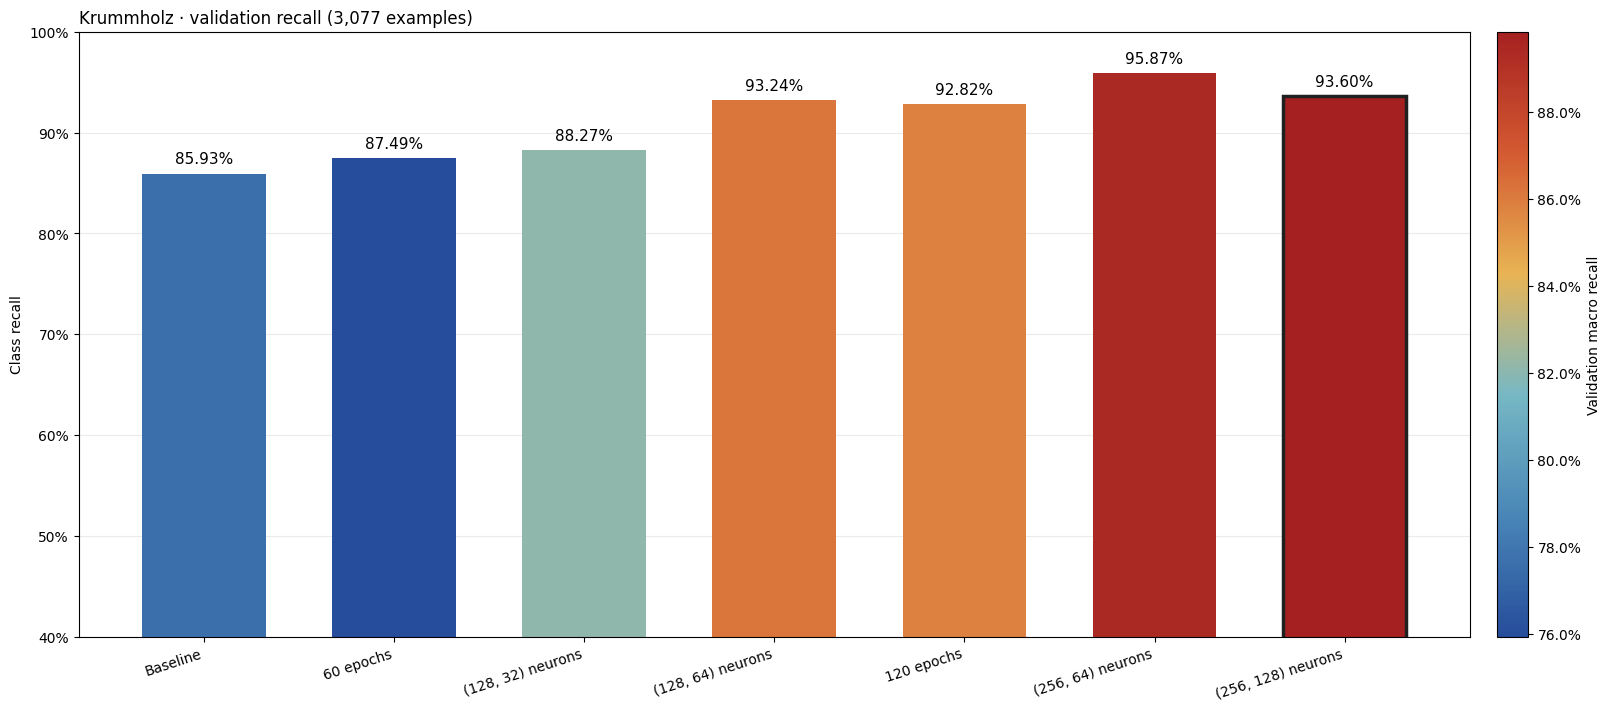

In [14]:
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from sklearn.metrics import recall_score

# The prediction arrays come from Steps 3–9, in experiment order.
validation_predictions = [
    val_predictions,
    longer_val_predictions,
    wider_val_predictions,
    second_val_predictions,
    longer_wide_predictions,
    new_predictions,
    candidate_predictions,
]

class_ids = sorted(cover_type_names)
recall_by_experiment = 100 * np.array([
    recall_score(
        y_val, predictions, labels=class_ids, average=None, zero_division=0
    )
    for predictions in validation_predictions
])

# Use one color scale across all seven figures.
macro_recall = recall_by_experiment.mean(axis=1)
color_scale = Normalize(vmin=macro_recall.min(), vmax=macro_recall.max())
cmap = LinearSegmentedColormap.from_list(
    "cool_to_warm",
    ["#264D9B", "#4986B7", "#77B8C4", "#E8B454", "#D45A31", "#A52121"],
)
experiment_colors = cmap(color_scale(macro_recall))

# Use the same y-axis across classes so bar heights are directly comparable.
lower_limit = max(0, 10 * np.floor((recall_by_experiment.min() - 3) / 10))
upper_limit = 100

for column, class_id in enumerate(class_ids):
    values = recall_by_experiment[:, column]
    support = np.count_nonzero(y_val == class_id)

    fig, ax = plt.subplots(figsize=figure_size, layout="constrained")
    bars = ax.bar(x, values, color=experiment_colors, width=0.65)
    bars[best_index].set_edgecolor("#202020")
    bars[best_index].set_linewidth(2.5)

    ax.bar_label(
        bars, labels=[f"{value:.2f}%" for value in values],
        padding=5, fontsize=11,
    )
    ax.set_title(
        f"{cover_type_names[class_id]} · validation recall ({support:,} examples)",
        loc="left",
    )
    ax.set_xticks(x, experiment_labels, rotation=18, ha="right")
    ax.set_ylabel("Class recall")
    ax.set_ylim(lower_limit, upper_limit)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)

    colorbar = fig.colorbar(
        ScalarMappable(norm=color_scale, cmap=cmap), ax=ax, pad=0.02
    )
    colorbar.set_label("Validation macro recall")
    colorbar.ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))

    plt.show()

A two-hidden-layer ReLU MLP with 256 and 128 neurons achieved 93.96% held-out test accuracy and 89.2% macro recall on CoverType. Widening the hidden layers improved validation accuracy more than increasing the epoch cap in the runs I compared. Cottonwood/Willow had the lowest test recall at 75.7%.